# Nghiên cứu Khoa học: Khảo sát (EDA), Tiền xử lý & Phân chia 5-Fold
**Đề tài:** Nghiên cứu mô hình học sâu đa phương thức kết hợp phân loại đa lớp và học thứ tự hỗ trợ phân loại mức độ gan nhiễm mỡ  
**Bộ dữ liệu:** Tongue-FLD (5.717 mẫu)  
**Tác giả:** Nguyễn Văn Trường - MSV: A48273 - Lớp: TI3602  
**Cán bộ hướng dẫn:** PGS.TS. Nguyễn Hoàng Phương  

---
### Mục tiêu của Notebook:
1. **Khảo sát dữ liệu (EDA):** Phân tích thống kê 8 chỉ số sinh lý, phân bố nhãn 3 mức độ bệnh, và kiểm tra ngẫu nhiên ảnh chụp lưỡi.
2. **Tiền xử lý dữ liệu (Preprocessing):** Mã hóa nhãn mục tiêu `0, 1, 2`, mã hóa biến phân loại giới tính, chuẩn hóa tên cột.
3. **Phân chia kiểm định chéo (Stratified 5-Fold Split):** Chia 5 phần phân tầng cố định nhằm bảo toàn tỷ lệ nhãn và chống rò rỉ dữ liệu (No Data Leakage).
4. **Xuất file dữ liệu:** Lưu kết quả vào `data/processed/tongue_fld_5folds.csv`.


## 1. Khai báo thư viện và cấu hình đường dẫn


In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import StratifiedKFold
from IPython.display import display

# Cấu hình thẩm mỹ cho biểu đồ
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11

# Đường dẫn thư mục
RAW_CSV_PATH = '../data/raw/clinical_data.csv'
IMAGES_DIR = '../data/raw/images'
PROCESSED_CSV_PATH = '../data/processed/tongue_fld_5folds.csv'

print("Đường dẫn CSV thô:", os.path.abspath(RAW_CSV_PATH))
print("Đường dẫn thư mục ảnh:", os.path.abspath(IMAGES_DIR))


Đường dẫn CSV thô: d:\Tai_lieu_hoc_tap\code\NCKH\data\raw\clinical_data.csv
Đường dẫn thư mục ảnh: d:\Tai_lieu_hoc_tap\code\NCKH\data\raw\images


## 2. Nạp dữ liệu bảng & Khám phá tổng quan


In [2]:
# Đọc dữ liệu
df = pd.read_csv(RAW_CSV_PATH)

print(f"Tổng số mẫu: {df.shape[0]:,} dòng")
print(f"Tổng số thuộc tính: {df.shape[1]} cột")
print("-" * 50)
df.info()
df.head()


Tổng số mẫu: 5,717 dòng
Tổng số thuộc tính: 10 cột
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5717 entries, 0 to 5716
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   quesid   5717 non-null   object 
 1   Gender   5717 non-null   object 
 2   Age      5717 non-null   int64  
 3   Height   5717 non-null   float64
 4   Waist    5717 non-null   float64
 5   Hipline  5717 non-null   float64
 6   Weight   5717 non-null   float64
 7   SBP      5717 non-null   int64  
 8   DBP      5717 non-null   int64  
 9   FLD      5717 non-null   object 
dtypes: float64(4), int64(3), object(3)
memory usage: 446.8+ KB


,quesid,Gender,Age,Height,Waist,Hipline,Weight,SBP,DBP,FLD
0,102220.jpg,_2,38,164.6,78.2,95.0,62.5,126,79,_0
1,100089.jpg,_2,45,160.9,77.0,92.6,55.0,107,63,_0
2,100413.jpg,_1,53,167.2,78.6,92.6,62.4,120,79,_0
3,105294.jpg,_2,63,151.0,93.0,99.0,65.7,126,96,_0
4,105295.jpg,_2,52,156.1,80.0,98.6,57.9,103,68,_0


### Kiểm tra giá trị thiếu (Missing / Null values)


In [3]:
missing_counts = df.isnull().sum()
print("Số lượng giá trị khuyết thiếu trong từng cột:")
print(missing_counts)

if missing_counts.sum() == 0:
    print("\n--> Dữ liệu hoàn chỉnh 100%, không có bất kỳ ô nào bị NaN / Null!")


Số lượng giá trị khuyết thiếu trong từng cột:
quesid     0
Gender     0
Age        0
Height     0
Waist      0
Hipline    0
Weight     0
SBP        0
DBP        0
FLD        0
dtype: int64

--> Dữ liệu hoàn chỉnh 100%, không có bất kỳ ô nào bị NaN / Null!


## 3. Phân tích phân bố nhãn bệnh (Class Distribution)
Nhãn mức độ gan nhiễm mỡ (`FLD`):
- `_0`: Không mắc gan nhiễm mỡ (Non-FLD)
- `_1`: Gan nhiễm mỡ mức độ nhẹ (Mild FLD)
- `_2`: Gan nhiễm mỡ mức độ vừa và nặng (Moderate / Severe FLD)


Bảng thống kê nhãn bệnh:


,Số lượng mẫu,Tỷ lệ (%)
FLD,,
_0,3690,64.54
_1,1512,26.45
_2,515,9.01


C:\Users\phung\AppData\Local\Temp\ipykernel_488\2982501191.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_counts.index, y=label_counts.values, palette=colors, ax=axes[0])


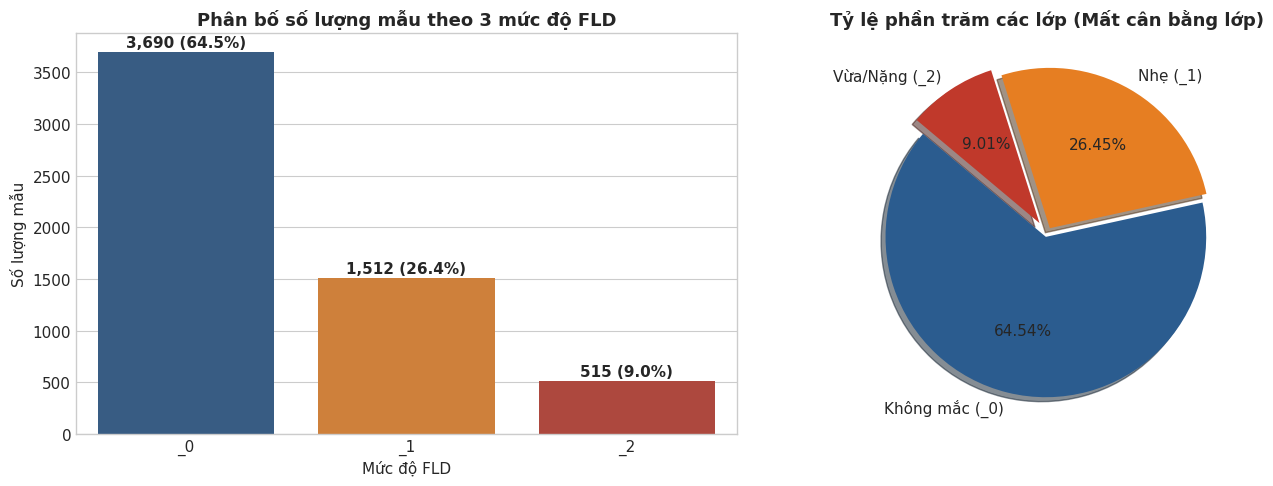

In [6]:
label_counts = df['FLD'].value_counts()
label_percent = df['FLD'].value_counts(normalize=True) * 100

summary_df = pd.DataFrame({
    'Số lượng mẫu': label_counts,
    'Tỷ lệ (%)': label_percent.round(2)
})
print("Bảng thống kê nhãn bệnh:")
display(summary_df)

# Trực quan hóa phân bố nhãn
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Biểu đồ Bar chart
colors = ['#2b5c8f', '#e67e22', '#c0392b']
sns.barplot(x=label_counts.index, y=label_counts.values, palette=colors, ax=axes[0])
axes[0].set_title('Phân bố số lượng mẫu theo 3 mức độ FLD', fontweight='bold', fontsize=13)
axes[0].set_xlabel('Mức độ FLD')
axes[0].set_ylabel('Số lượng mẫu')
for i, v in enumerate(label_counts.values):
    axes[0].text(i, v + 50, f"{v:,} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')

# 2. Biểu đồ Pie chart
labels_desc = ['Không mắc (_0)', 'Nhẹ (_1)', 'Vừa/Nặng (_2)']
axes[1].pie(label_counts.values, labels=labels_desc, autopct='%1.2f%%', startangle=140, 
            colors=colors, explode=(0.02, 0.04, 0.08), shadow=True)
axes[1].set_title('Tỷ lệ phần trăm các lớp (Mất cân bằng lớp)', fontweight='bold', fontsize=13)

plt.tight_layout()
plt.show()


## 4. Khảo sát các chỉ số sinh lý (Clinical Indicators)
8 chỉ số sinh lý lâm sàng gồm:
1. `Gender`: Giới tính (`_1`: Nam, `_2`: Nữ)
2. `Age`: Tuổi (từ 35 đến 75)
3. `Height`: Chiều cao (cm)
4. `Weight`: Cân nặng (kg)
5. `Waist`: Vòng eo (cm)
6. `Hipline`: Vòng hông (cm)
7. `SBP`: Huyết áp tâm thu (Systolic Blood Pressure - mmHg)
8. `DBP`: Huyết áp tâm trương (Diastolic Blood Pressure - mmHg)


In [7]:
numeric_cols = ['Age', 'Height', 'Waist', 'Hipline', 'Weight', 'SBP', 'DBP']
print("Bảng thống kê mô tả 7 chỉ số số học:")
display(df[numeric_cols].describe().round(2))


Bảng thống kê mô tả 7 chỉ số số học:


,Age,Height,Waist,Hipline,Weight,SBP,DBP
count,5717.00,5717.00,5717.00,5717.00,5717.00,5717.00,5717.00
mean,55.01,160.42,81.35,93.57,62.09,129.18,82.74
std,10.09,7.91,9.69,6.56,10.44,19.25,10.92
min,35.00,120.90,53.00,64.80,20.40,80.00,48.00
25%,48.00,154.70,74.20,89.20,54.60,115.00,75.00
50%,55.00,159.90,81.00,93.00,60.90,127.00,82.00
75%,63.00,165.70,88.00,97.40,68.40,141.00,89.00
max,75.00,190.40,125.00,162.60,111.50,217.00,135.00


### Khảo sát phân bố Giới tính theo mức độ bệnh


Bảng phân phối Giới tính x Mức độ bệnh:


FLD,_0,_1,_2,All
Gender,,,,
_1,1219,681,237,2137
_2,2471,831,278,3580
All,3690,1512,515,5717


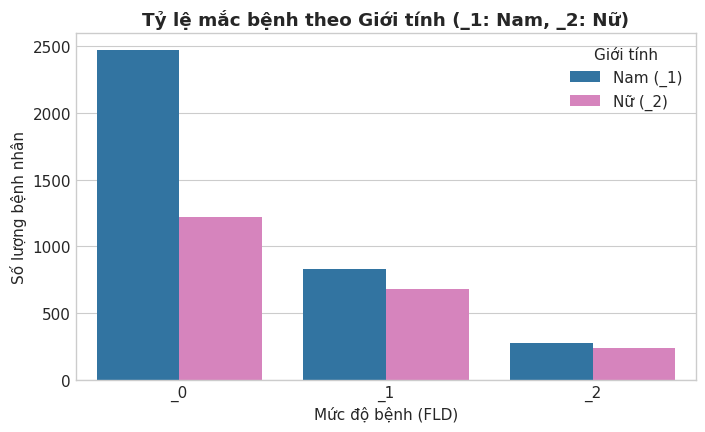

In [8]:
gender_crosstab = pd.crosstab(df['Gender'], df['FLD'], margins=True)
print("Bảng phân phối Giới tính x Mức độ bệnh:")
display(gender_crosstab)

plt.figure(figsize=(8, 4.5))
sns.countplot(data=df, x='FLD', hue='Gender', palette=['#1f77b4', '#e377c2'])
plt.title('Tỷ lệ mắc bệnh theo Giới tính (_1: Nam, _2: Nữ)', fontweight='bold')
plt.xlabel('Mức độ bệnh (FLD)')
plt.ylabel('Số lượng bệnh nhân')
plt.legend(title='Giới tính', labels=['Nam (_1)', 'Nữ (_2)'])
plt.show()


### Trực quan hóa phân phối các chỉ số lâm sàng theo từng mức độ bệnh


C:\Users\phung\AppData\Local\Temp\ipykernel_488\2617159917.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='FLD', y=col, palette='Set2', ax=axes[idx])
C:\Users\phung\AppData\Local\Temp\ipykernel_488\2617159917.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='FLD', y=col, palette='Set2', ax=axes[idx])
C:\Users\phung\AppData\Local\Temp\ipykernel_488\2617159917.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='FLD', y=col, palette='Set2', ax=axes[idx])
C:\Users\phung\AppData\Local\Temp\ipykernel_488\2

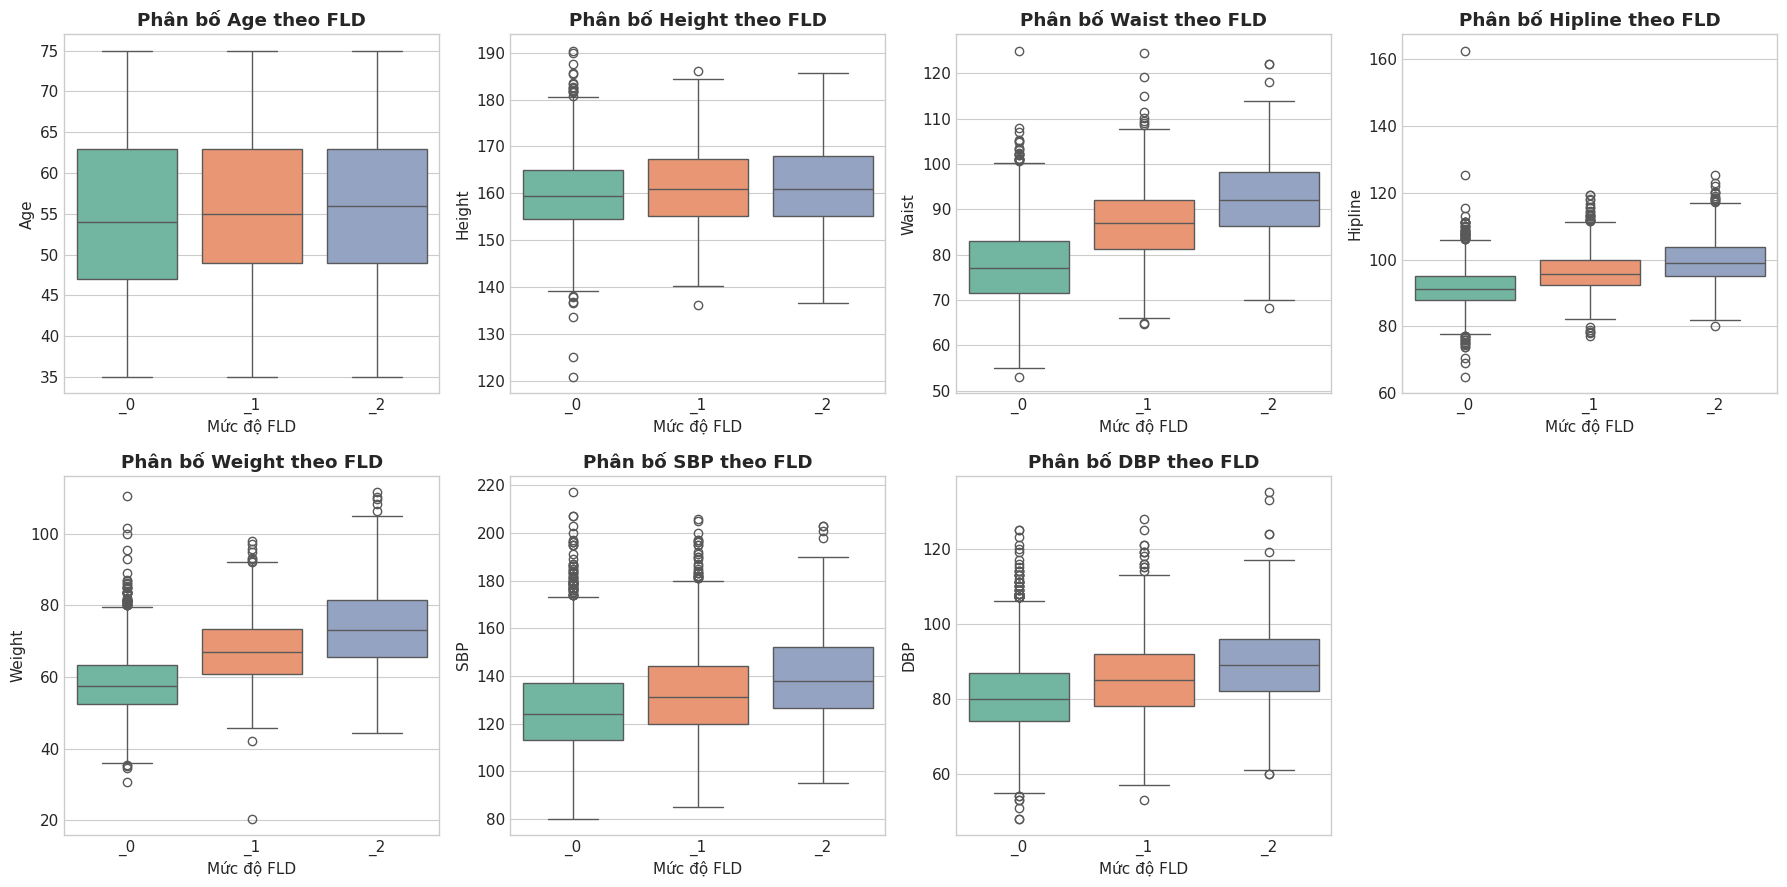

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for idx, col in enumerate(numeric_cols):
    sns.boxplot(data=df, x='FLD', y=col, palette='Set2', ax=axes[idx])
    axes[idx].set_title(f'Phân bố {col} theo FLD', fontweight='bold')
    axes[idx].set_xlabel('Mức độ FLD')

# Ẩn subplot thừa thứ 8
axes[-1].axis('off')
plt.tight_layout()
plt.show()


### Ma trận tương quan giữa các chỉ số sinh lý


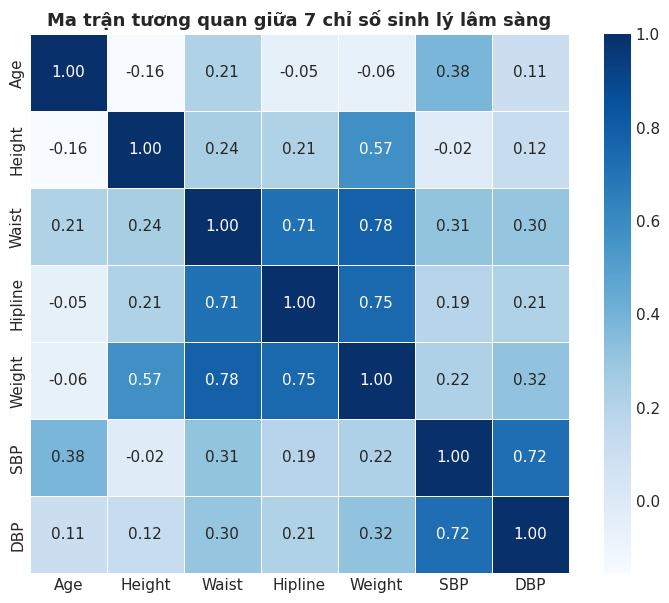

In [10]:
plt.figure(figsize=(9, 7))
corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', square=True, linewidths=0.5)
plt.title('Ma trận tương quan giữa 7 chỉ số sinh lý lâm sàng', fontweight='bold', fontsize=13)
plt.show()


## 5. Khảo sát dữ liệu ảnh chụp lưỡi (Tongue Images)


Tổng số ảnh trong thư mục: 5,717 ảnh


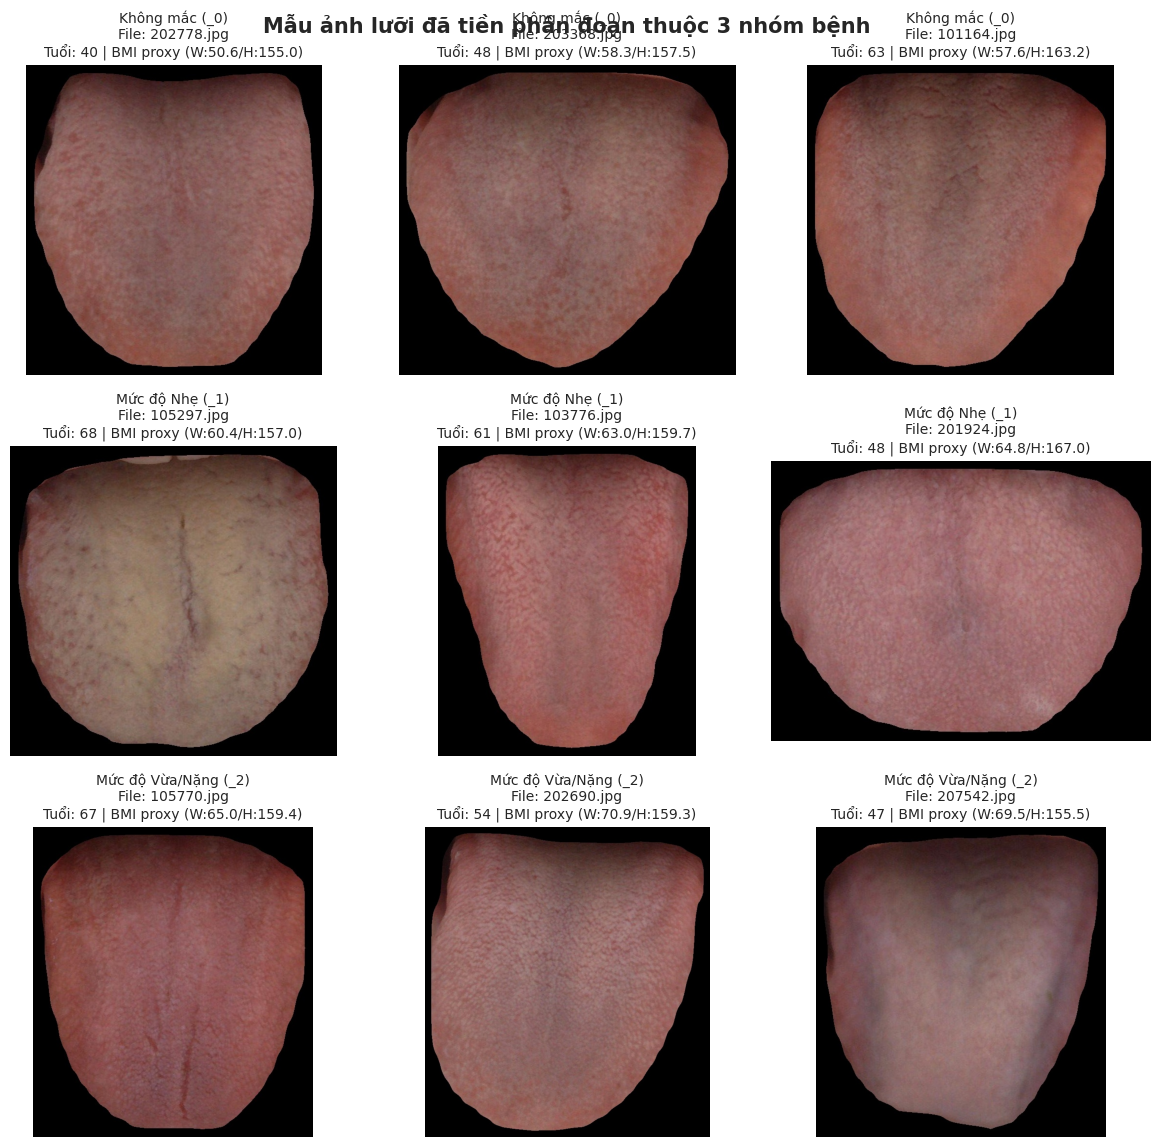

In [11]:
# Kiểm tra số lượng ảnh trong thư mục
all_images = [f for f in os.listdir(IMAGES_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
print(f"Tổng số ảnh trong thư mục: {len(all_images):,} ảnh")

# Hiển thị ngẫu nhiên 9 ảnh đại diện cho 3 nhóm bệnh
np.random.seed(42)
sample_0 = df[df['FLD'] == '_0'].sample(3, random_state=42)
sample_1 = df[df['FLD'] == '_1'].sample(3, random_state=42)
sample_2 = df[df['FLD'] == '_2'].sample(3, random_state=42)
samples = pd.concat([sample_0, sample_1, sample_2])

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes = axes.flatten()

label_names = {'_0': 'Không mắc (_0)', '_1': 'Mức độ Nhẹ (_1)', '_2': 'Mức độ Vừa/Nặng (_2)'}

for idx, (_, row) in enumerate(samples.iterrows()):
    img_path = os.path.join(IMAGES_DIR, row['quesid'])
    img = Image.open(img_path)
    axes[idx].imshow(img)
    axes[idx].set_title(f"{label_names[row['FLD']]}\nFile: {row['quesid']}\nTuổi: {row['Age']} | BMI proxy (W:{row['Weight']}/H:{row['Height']})", fontsize=10)
    axes[idx].axis('off')

plt.suptitle('Mẫu ảnh lưỡi đã tiền phân đoạn thuộc 3 nhóm bệnh', fontsize=15, fontweight='bold', y=0.95)
plt.tight_layout()
plt.show()


## 6. Tiền xử lý dữ liệu (Data Preprocessing)
Thực hiện các bước chuẩn hóa:
1. Đổi tên `quesid` $\rightarrow$ `image_name` (khớp với PyTorch Dataset).
2. Mã hóa nhãn `FLD`: `'_0'` $\rightarrow$ `0`, `'_1'` $\rightarrow$ `1`, `'_2'` $\rightarrow$ `2` (tạo cột `label`).
3. Mã hóa giới tính `Gender`: `'_1'` (Nam) $\rightarrow$ `1`, `'_2'` (Nữ) $
ightarrow$ `0`.


In [12]:
# Tạo bản sao sạch để xử lý
clean_df = df.copy()

# 1. Đổi tên cột định danh ảnh
clean_df.rename(columns={'quesid': 'image_name'}, inplace=True)

# 2. Mã hóa nhãn FLD thành số nguyên 0, 1, 2
label_mapping = {'_0': 0, '_1': 1, '_2': 2}
clean_df['label'] = clean_df['FLD'].map(label_mapping).astype(int)

# 3. Mã hóa Gender thành nhị phân (1: Nam, 0: Nữ)
gender_mapping = {'_1': 1, '_2': 0}
clean_df['Gender'] = clean_df['Gender'].map(gender_mapping).astype(int)

print("Cấu trúc bảng sau khi làm sạch:")
display(clean_df[['image_name', 'Gender', 'Age', 'Height', 'Weight', 'FLD', 'label']].head())


Cấu trúc bảng sau khi làm sạch:


,image_name,Gender,Age,Height,Weight,FLD,label
0,102220.jpg,0,38,164.6,62.5,_0,0
1,100089.jpg,0,45,160.9,55.0,_0,0
2,100413.jpg,1,53,167.2,62.4,_0,0
3,105294.jpg,0,63,151.0,65.7,_0,0
4,105295.jpg,0,52,156.1,57.9,_0,0


In [13]:
clean_df.head()

,image_name,Gender,Age,Height,Waist,Hipline,Weight,SBP,DBP,FLD,label
0,102220.jpg,0,38,164.6,78.2,95.0,62.5,126,79,_0,0
1,100089.jpg,0,45,160.9,77.0,92.6,55.0,107,63,_0,0
2,100413.jpg,1,53,167.2,78.6,92.6,62.4,120,79,_0,0
3,105294.jpg,0,63,151.0,93.0,99.0,65.7,126,96,_0,0
4,105295.jpg,0,52,156.1,80.0,98.6,57.9,103,68,_0,0


## 7. Phân chia 5-Fold Phân tầng Cố định (Stratified 5-Fold Split)
* **Phương pháp:** Sử dụng `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` dựa trên cột `label`.
* **Mục tiêu:** Giữ nguyên tỷ lệ 3 lớp nhãn cân đối ở cả 5 phần.
* **Lưu file cố định:** Xuất ra `data/processed/tongue_fld_5folds.csv` để cả 6 mô hình M1 $\rightarrow$ M6 đều dùng chung tập chia này.


In [14]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

clean_df['fold'] = -1
for fold_idx, (train_idx, val_idx) in enumerate(skf.split(clean_df, clean_df['label'])):
    clean_df.loc[val_idx, 'fold'] = fold_idx

print("Số lượng mẫu ở từng fold:")
print(clean_df['fold'].value_counts().sort_index())

print("\nKiểm tra tỷ lệ phân bố nhãn bệnh trên từng fold (Đảm bảo phân tầng):")
fold_distribution = pd.crosstab(clean_df['fold'], clean_df['label'], normalize='index') * 100
display(fold_distribution.round(2))


Số lượng mẫu ở từng fold:
fold
0    1144
1    1144
2    1143
3    1143
4    1143
Name: count, dtype: int64

Kiểm tra tỷ lệ phân bố nhãn bệnh trên từng fold (Đảm bảo phân tầng):


label,0,1,2
fold,,,
0,64.51,26.49,9.00
1,64.51,26.49,9.00
2,64.57,26.42,9.01
3,64.57,26.42,9.01
4,64.57,26.42,9.01


## 8. Xuất file dữ liệu hoàn chỉnh


In [15]:
os.makedirs(os.path.dirname(PROCESSED_CSV_PATH), exist_ok=True)
clean_df.to_csv(PROCESSED_CSV_PATH, index=False)

print(f"--> ĐÃ LƯU FILE DỮ LIỆU CHIA 5-FOLD THÀNH CÔNG TẠI:\n{os.path.abspath(PROCESSED_CSV_PATH)}")
print(f"Tổng số dòng: {len(clean_df):,}")
print("Các cột trong file đã lưu:")
print(list(clean_df.columns))


--> ĐÃ LƯU FILE DỮ LIỆU CHIA 5-FOLD THÀNH CÔNG TẠI:
d:\Tai_lieu_hoc_tap\code\NCKH\data\processed\tongue_fld_5folds.csv
Tổng số dòng: 5,717
Các cột trong file đã lưu:
['image_name', 'Gender', 'Age', 'Height', 'Waist', 'Hipline', 'Weight', 'SBP', 'DBP', 'FLD', 'label', 'fold']
